170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3172s 19us/step
Training images: (8000, 32, 32, 3)
Validation images: (2000, 32, 32, 3)
Testing images: (2000, 32, 32, 3)


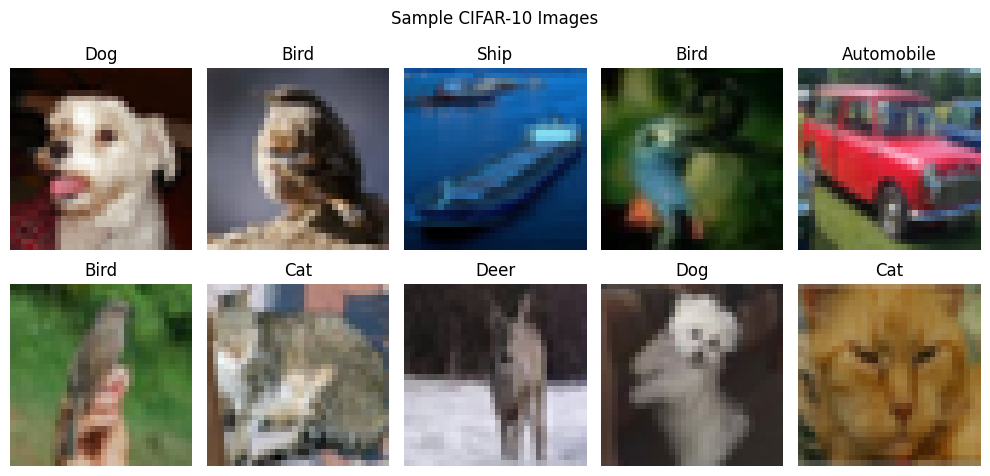

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 103ms/step - accuracy: 0.3194 - loss: 1.8794 - val_accuracy: 0.4070 - val_loss: 1.6445
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 106ms/step - accuracy: 0.4775 - loss: 1.4731 - val_accuracy: 0.4620 - val_loss: 1.4856
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.5393 - loss: 1.3045 - val_accuracy: 0.4970 - val_loss: 1.3973
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.5839 - loss: 1.1825 - val_accuracy: 0.5050 - val_loss: 1.3933
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.6241 - loss: 1.0789 - val_accuracy: 0.5310 - val_loss: 1.3425
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 22s 105ms/step - accuracy: 0.6628 - loss: 0.9717 - val_accuracy: 0.5510 - val_loss: 1.3062
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - accuracy: 0.6906 - loss: 0.8877 - val_accuracy: 0.5725 - val_loss: 1.2633
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.7228 - loss: 0.8

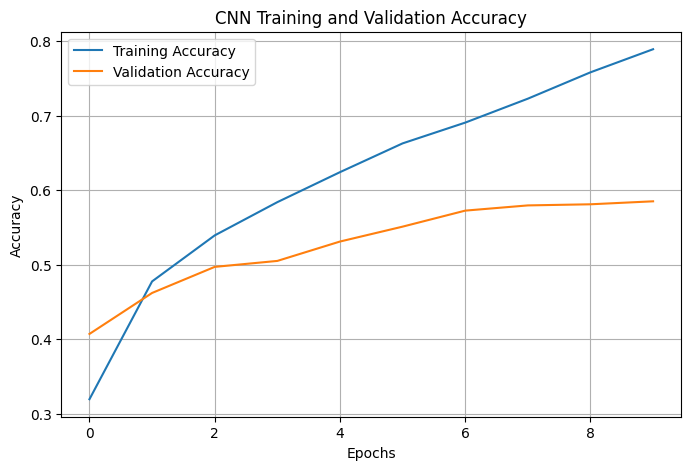

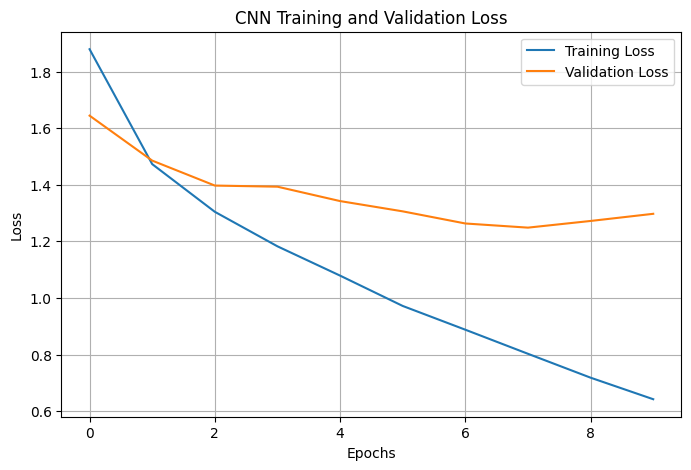

<Figure size 1000x800 with 0 Axes>

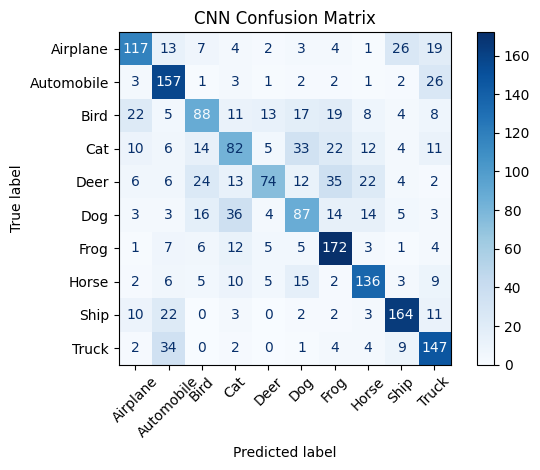


Number of Misclassified Images: 776


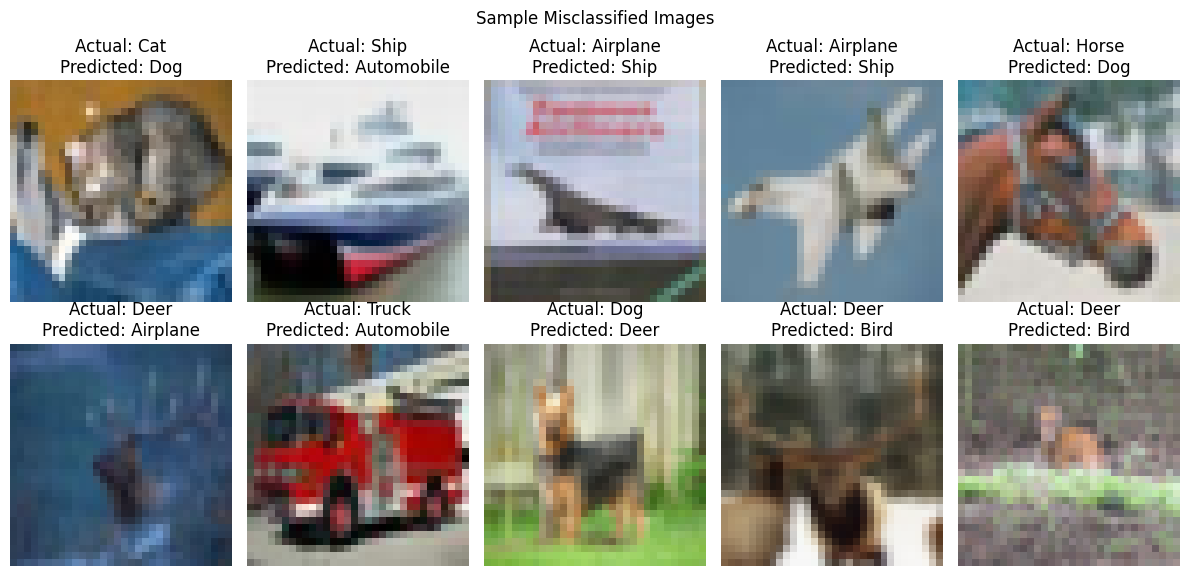

AttributeError: The layer sequential_13 has never been called and thus has no defined input.

In [14]:
# EXPERIMENT 11: CNN FOR IMAGE CLASSIFICATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. LOAD CIFAR-10 DATASET
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Use a smaller subset for faster training
x_train = x_train[:10000]
y_train = y_train[:10000]

x_test = x_test[:2000]
y_test = y_test[:2000]

# 2. NORMALISE IMAGES
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

# Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)

# 3. DISPLAY SAMPLE IMAGES
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

# 4. BUILD CNN MODEL
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

# 5. COMPILE MODEL
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 6. TRAIN CNN MODEL
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1
)

# 7. EVALUATE MODEL
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("\nMODEL EVALUATION")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 8. PLOT ACCURACY
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 9. PLOT LOSS
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# 10. PREDICT TEST IMAGES
predictions = model.predict(x_test, verbose=0)
y_pred = np.argmax(predictions, axis=1)

# 11. CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap='Blues', xticks_rotation=45)
plt.title('CNN Confusion Matrix')
plt.tight_layout()
plt.show()

# 12. DISPLAY MISCLASSIFIED IMAGES
wrong = np.where(y_pred != y_test)[0]

print("\nNumber of Misclassified Images:", len(wrong))

plt.figure(figsize=(12, 6))

for i, index in enumerate(wrong[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[index])
    plt.title(
        "Actual: " + class_names[y_test[index]] +
        "\nPredicted: " + class_names[y_pred[index]]
    )
    plt.axis('off')

plt.suptitle("Sample Misclassified Images")
plt.tight_layout()
plt.show()

# 13. VISUALISE FIRST CONVOLUTION LAYER FEATURE MAPS
feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[0].output
)

sample_image = x_test[0:1]
feature_maps = feature_model.predict(sample_image, verbose=0)

plt.figure(figsize=(12, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title("Filter " + str(i + 1))
    plt.axis('off')

plt.suptitle("First Convolution Layer Feature Maps")
plt.tight_layout()
plt.show()

print("\nExperiment 11 Completed Successfully!")